# Hyper Instancing Meshes in a BIM Model - 4

In this multi-part project, we are attempting to reduce the memory footprint of large BIM models by consolidating duplicate geometry into one. In [part 3](hyper-instance-3.ipynb) of this notebook we were able to successfully consolidate all our straight runs of pipe into one unit cylinder, which we then combined with a series of transformation matrix to essentially recreate our scene. The hardest part was finding the transformation matrix in the first place, for which we used PCA on the covariance matrix (see [part 1](hyper-instance.ipynb)). Our goal in this notebook will be to tackle a slightly more difficult, but still extremely high-frequency geometry- 90 degree bends.

## Import of Modules and Packages

In [2]:
import numpy as np
import pygltflib
import pymeshlab
import ifcopenshell
import ifcopenshell.geom
import ifcopenshell.util.shape
import matplotlib.pyplot as plt

## Basic EDA

Instancing our 90 degree bends turns out to not be as easy as the straight pipes. Here is a sample of 90 degree bends from the model.

![Sample of 90 degree elbows from BIM model](../img/90deg-bend-fitting-samples.png)

We observe a general theme here, although we do note that in this case we do have some conflicting geometry. For example, the first object in the poisitive Red axis looks different to the first object in the negative red axis. Even though there may be similarities, the geometry is no longer exactly captured through transformation matrices.

That said, since the goal is to create simple effective communication- and not strict accuracy, we might be able to substitute these objects for one simple 90 degree bend geometry. Even better- we may be able to substitute this geometry into 2 45 degree bends, thereby even further simplifying our geometry as we can also capture the 45 degree bends with this one piece of geometry.

One step at a time. Looking in the figure above, its not immediately clear why some items are not the same geometry. Take for instance the first object in the negative green axis, and the first object in the negative red.

![Comparison of samples 90 degree bends](../img/90deg-bend-fitting-samples-comparison.png)

The model says these 2 geometries are entirely unique. However, aside from their orientation, I struggle to tell them apart. In fact, if we apply 2 rotations on the left object- one clockwise about the green axis, and one counterclockwise about the red, this is what we get.

![Comparison of samples 90 degree bends after rotation](../img/90deg-bend-fitting-samples-comparison-rotationapplied.png)

That looks like literally the same object.

Let's load up the raw data and see what we can work with.

In [3]:
ms = pymeshlab.MeshSet()
ms.load_new_mesh('data/90degbend-orig.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
f_matrix = m.face_matrix()

In [4]:
v_matrix.shape

(1352, 3)

In [5]:
f_matrix.shape

(904, 3)

Aside, we see that one simple bend contains ~20 times more individual vertices than our simple pipe (64) from earlier. Crazy.

Let's also load up our sample bend and see what we get.

In [6]:
ms.load_new_mesh('data/90degbend-sample.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
f_matrix_test = m.face_matrix()

In [7]:
v_matrix_test.shape

(1352, 3)

In [8]:
f_matrix_test.shape

(904, 3)

Interesting. Seems like they have the same number of vertices.

Let's acquire our plotting function from earlier and see what these look like.

In [9]:
def plot_vertices(vertices):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    ax.scatter(vertices[:,0], vertices[:,1], vertices[:,2], color='grey')

    return ax

<Axes3D: >

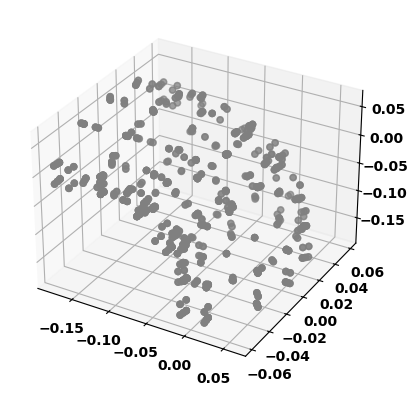

In [10]:
plot_vertices(v_matrix)

<Axes3D: >

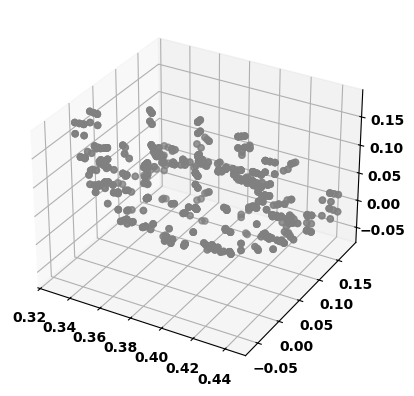

In [11]:
plot_vertices(v_matrix_test)

This confirms that we're dealing with 2 completely separate meshes. To confirm, this is the corresponding orientation we're dealing with.

![Orientation of given widgets](../img/90deg-bend-fitting-samples-comparison-with-plot.png)

Lets get some more stats.

In [12]:
np.mean(v_matrix, axis=0)

array([-6.07087840e-02,  2.46351263e-19, -6.04368173e-02])

In [13]:
np.max(v_matrix, axis=0)

array([0.060638, 0.058571, 0.060638])

In [14]:
np.min(v_matrix, axis=0)

array([-0.179681, -0.058571, -0.179681])

In [15]:
np.mean(v_matrix_test, axis=0)

array([0.38548269, 0.06070876, 0.06043682])

In [16]:
np.max(v_matrix_test, axis=0)

array([0.444054, 0.179681, 0.179681])

In [17]:
np.min(v_matrix_test, axis=0)

array([ 0.326911, -0.060638, -0.060638])

Since our objects are not aligned in space, let's subtract the mean from each one to center them at their centroid.

In [18]:
v_matrix_norm = v_matrix - np.mean(v_matrix, axis=0)
np.mean(v_matrix_norm, axis=0)

array([ 1.57664808e-17,  2.46351263e-19, -2.62774680e-18])

In [19]:
v_matrix_test_norm = v_matrix_test - np.mean(v_matrix_test, axis=0)
np.mean(v_matrix_test_norm, axis=0)

array([2.16789111e-17, 0.00000000e+00, 7.88324041e-18])

Both meshes appear to be centered. What are their extents?

In [20]:
np.max(v_matrix_norm, axis=0)

array([0.12134678, 0.058571  , 0.12107482])

In [21]:
np.max(v_matrix_test_norm, axis=0)

array([0.05857131, 0.11897224, 0.11924418])

At first glance, it looks like the meshes are different, but we note that their orientation is not the same hence their extents will also be different. We know that the mesh is rotated, so we should observe similarities in extents within different axes, and we do see that the X dimension of the first aligns well with the Z dimension of the second, Y aligns with X, and X aligns with Y.

As a final step, lets see what these aligned objects look like in space.

<Axes3D: >

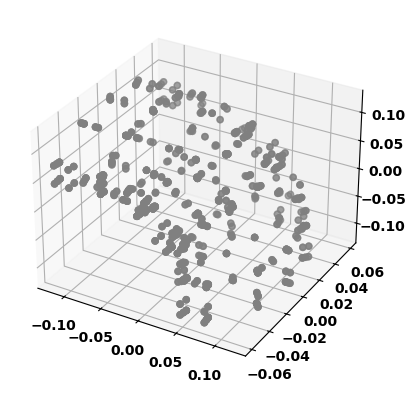

In [22]:
plot_vertices(v_matrix_norm)

<Axes3D: >

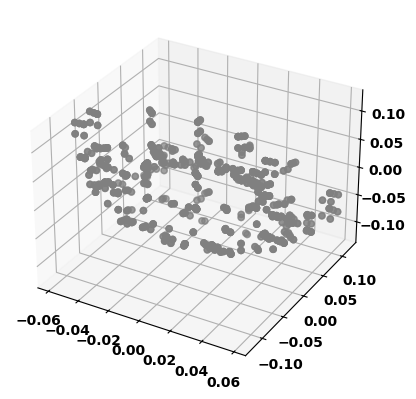

In [23]:
plot_vertices(v_matrix_test_norm)

## Finding the Covariance Matrix

When working with straight pipes, it was relatively easy to estimate the pose from the covariance matrix. The longest eigenvector was usually the one corresponding to the length axis, and the other 2 would have been equal. In the case of the 90 degree bend however, its not as simple. Our object is not symmetric hence estimating its principal components might not be as deterministic.

Let's first see what the covariance matrices look like for each of our shapes.

In [24]:
cov_mat = np.round(np.cov(v_matrix_norm, rowvar=False),4)
cov_mat

array([[ 0.0045,  0.    , -0.0027],
       [ 0.    ,  0.0015, -0.    ],
       [-0.0027, -0.    ,  0.0045]])

In [25]:
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
cov_mat_test

array([[ 0.0015, -0.    ,  0.    ],
       [-0.    ,  0.0045, -0.0027],
       [ 0.    , -0.0027,  0.0045]])

As expected, we see values showing up again across dimensions. In the first example, we see a weak negative relationship between X and Y. This is what our shape looks like in 3D space, when viewed down this plane.

![90 degree bend viewed down -Y axis](../img/90degbend-x-y-plane.png)

This makes sense. As we decrease our values of X, we get smaller corresponding values for Y.

Whereas, in our test shape, we observe a positive relationship between X and Z. Here is the orientation of this object when viewed down this plane.

![90 degree bend viewed down +X axis](../img/90degbend-x-z-planepng.png)

Given the high degree of similarity between our covariance, I'd have expected the orientation to match exactly- just the signs flipped when viewed down this axis. Perhaps we're making a mistake somewhere in the orientation?

Research into the matter yields that the choice of axis is important. We exported this object under default conditions, which means using Y=up and -Z=forward. However, since we exported both meshes under the same orientation, this should not matter. The only difference it would make is when trying to align it back with Blender. As we see, the Z axis in numpy does not necessarily imply Z axis in Blender.

To confirm, we apply a rotation to our sample object along the X axis to give it some sort of alignment and see what the resulting vertex matrix looks like.

In [26]:
ms.load_new_mesh('data/90degbend-sample-1.obj')

m = ms.current_mesh()

v_matrix_test_1 = m.vertex_matrix()
f_matrix_test_1 = m.face_matrix()

<Axes3D: >

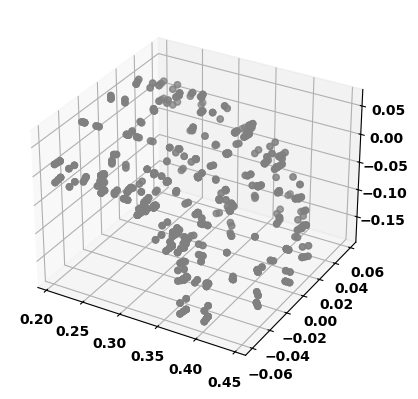

In [27]:
plot_vertices(v_matrix_test_1)

<Axes3D: >

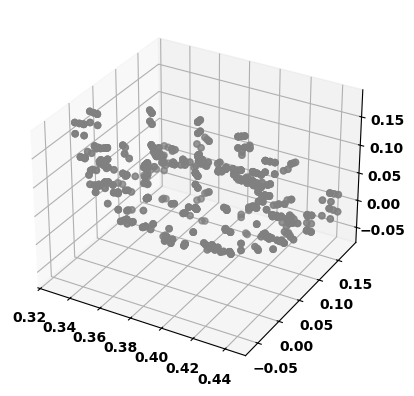

In [28]:
plot_vertices(v_matrix_test)

I think we will come back to this issue later if problems persist. For now, since we can confirm that the coordinate system is the same for each of the exported meshes, regardless of which direction is up and forward, our calculations should align.

## Calculating Eigenvectors

In the straight pipe example, the eigenvectors of the covariance matrix gave us the degree of rotation needed to transform our unit pipe. The logic behind that was, our original unit pipe had a definite direction of maximum covariance (the length axis). If we could find the length axis of the sample pipe (by finding the local direction of highest spread), we could find the rotation amount. This worked well since we knew that simple pipes had one definite axis with larger / different covariance than the rest.

In our 90 degree bend, things are not so straightforward. Or are they? We observe one unique value for covariance in our sample shape.

In [29]:
cov_mat

array([[ 0.0045,  0.    , -0.0027],
       [ 0.    ,  0.0015, -0.    ],
       [-0.0027, -0.    ,  0.0045]])

In [30]:
cov_mat_test

array([[ 0.0015, -0.    ,  0.    ],
       [-0.    ,  0.0045, -0.0027],
       [ 0.    , -0.0027,  0.0045]])

Let's just see what the eigenvectors look like for our test object.

In [31]:
eg_val, eg_vec = np.linalg.eigh(cov_mat_test)
eg_vec

array([[ 1.        , -0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678]])

In [32]:
eg_val

array([0.0015, 0.0018, 0.0072])

We know that the eigenvalues give us the directions of maximum covariance. In this case, our 3rd eigenvalue is largest, meaning the Z axis has the largest covariance. We need to align this with our observed covariance in the sample object.

What is the covariance matrix of our sample?

In [33]:
eg_val_org, eg_vec_org = np.linalg.eigh(cov_mat)
eg_vec_org

array([[-1.71189817e-15, -7.07106781e-01, -7.07106781e-01],
       [ 1.00000000e+00, -2.55351296e-15,  1.11022302e-16],
       [-1.55431223e-15, -7.07106781e-01,  7.07106781e-01]])

In [34]:
eg_val_org

array([0.0015, 0.0018, 0.0072])

As a reminder, this is what our original object looked like.

<Axes3D: >

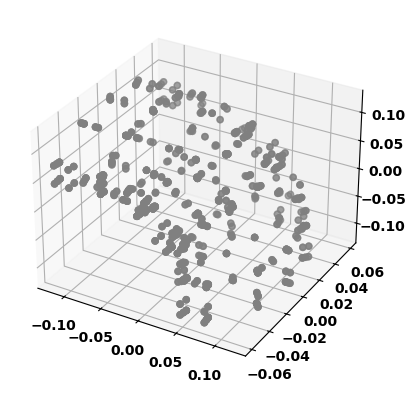

In [35]:
plot_vertices(v_matrix_norm)

And the sample.

<Axes3D: >

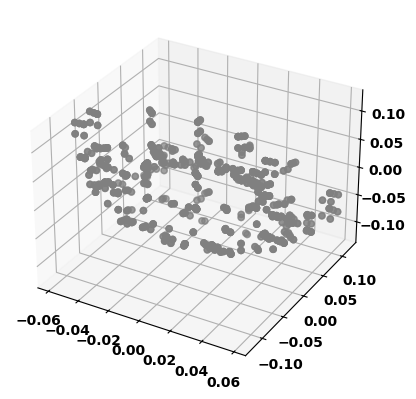

In [36]:
plot_vertices(v_matrix_test_norm)

The original object has the Z variable corresponding to the highest covariance, followed by Y and X. We will need to sort our derived eigenvectors based on this information- the largest one will go in the Z slot, second largest in Y and so on. In this case, its seems like the order is aligned. Hence we can calculate the rotation matrix, by first reordering our eigenvectors.

In [37]:
reorder_eg_vec = eg_vec[:, np.argsort(eg_val)]
reorder_eg_vec

array([[ 1.        , -0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678]])

In this case, our sorted eigenvectors are the same.

The rotation matrix is calculated as an identity 4x4 matrix with the `reorder_eg_vec` matrix in the top 3x3 quadrant.

In [38]:
test_rotation_matrix = np.eye(4,4)
test_rotation_matrix[:3, :3] = reorder_eg_vec
test_rotation_matrix

array([[ 1.        , -0.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678,  0.        ],
       [ 0.        , -0.70710678,  0.70710678,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

Now theoretically, if we multiply this matrix by our original vertices, we should get the correct orientation? Lets see.

Original Shape.

<Axes3D: >

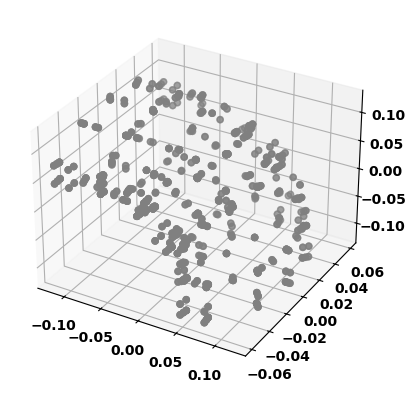

In [39]:
plot_vertices(v_matrix_norm)

Sample Shape.

<Axes3D: >

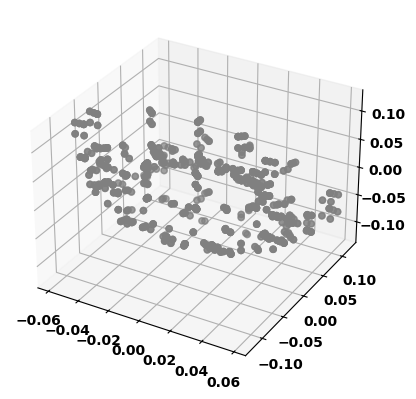

In [40]:
plot_vertices(v_matrix_test_norm)

Transformed vertices.

<Axes3D: >

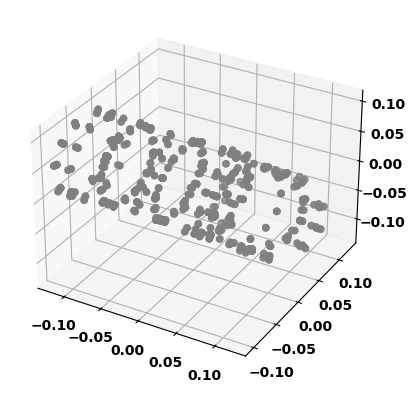

In [41]:
v_matrix_transformed = test_rotation_matrix @ np.transpose(np.c_[v_matrix_norm, np.ones(v_matrix_norm.shape[0])])
plot_vertices(np.transpose(v_matrix_transformed)[:, :3])

That does not look quite right.

## Attempt 2

To start off with, lets add some axis labels on our vertex chart so we can get our bearings. We redefine our `plot_vertices` function from earlier. We also add the ability to shade the vertices by their depth- in this case the Y value, so we can see which ones are closer to the front than others.

In [42]:
def plot_vertices(vertices):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    ax.scatter(vertices[:,0], vertices[:,1], vertices[:,2], c=vertices[:,1], cmap='grey')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    return ax

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

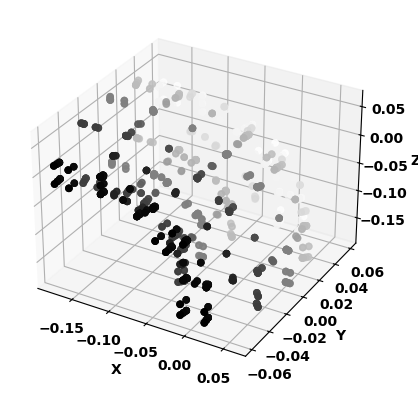

In [43]:
plot_vertices(v_matrix)

Another tweak I'd like to make is to ensure absolutely proper alignment between our Blender exported mesh and the numpy loaded mesh. This relates to the forward, up direction confusion we had from earlier. We orient our sample object like so.

![New Sample 90 Deg Bend for Testing](../img/new-sample-pipe.png)

This new object is constrained to the positive quadrant (yes there is a litte that goes negative, but mostly). We want to export this best such that its orientation lines up with what we see in matplotlib and numpy. Our first option is the Blender default: Forward Axis -Z, Up Axis Y.

This is what the object looks like in matplotlib 3d space.

In [44]:
ms.load_new_mesh('data/90degbend-orig-2.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
v_matrix

array([[ 0.025456,  0.      ,  0.015556],
       [ 0.025456,  0.      ,  0.015556],
       [ 0.025456,  0.      ,  0.015556],
       ...,
       [ 0.014947,  0.055782, -0.121681],
       [ 0.014947,  0.055782, -0.121681],
       [ 0.014947,  0.055782, -0.121681]], shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

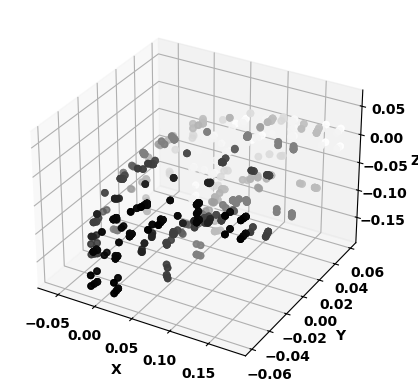

In [45]:
plot_vertices(v_matrix)

Something does not seem quite right- the shape seems off. Let's try another export method. Here, we try Forward= -Y, Up= Z.

In [46]:
ms.load_new_mesh('data/90degbend-orig-3.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
v_matrix

array([[-0.025456,  0.015556,  0.      ],
       [-0.025456,  0.015556,  0.      ],
       [-0.025456,  0.015556,  0.      ],
       ...,
       [-0.014947, -0.121681,  0.055782],
       [-0.014947, -0.121681,  0.055782],
       [-0.014947, -0.121681,  0.055782]], shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

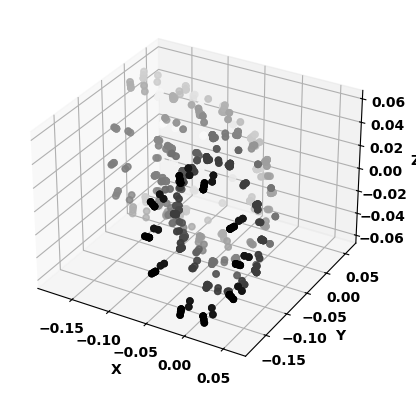

In [47]:
plot_vertices(v_matrix)

Seems like the X and Y directions might have been flipped. Let's try one more export- Forward Axis= Y, Up=Z

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

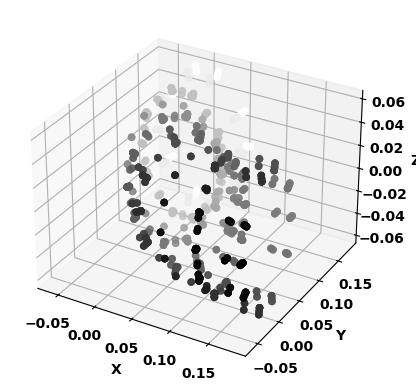

In [48]:
ms.load_new_mesh('data/90degbend-orig-4.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
plot_vertices(v_matrix)

Now we see some alignment. As a reminder, this is what our object looks like in the Blender viewport.

![90 Degree Bend Sample 4](../img/90degbend-sample-4.png)

Let's also export our test mesh using the same export settings. As a reminder, choosing the export settings will not matter as long as we're consistent, since the eigen transforms will work regardless. We are going through this process since I'd like to be able to adequately verify what axes are being rotated and why.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

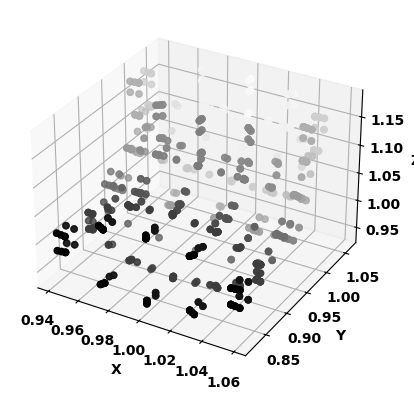

In [49]:
ms.load_new_mesh('data/90degbend-test-4.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

![90 Degree Bend test object 4](../img/90degbend-test-object.png)

As a side, we have also given this object translation values of (1,1,1), so our vertices will definitely need to be centered before we do anything. Let's do that now.

In [50]:
v_matrix_norm = v_matrix - np.mean(v_matrix, axis=0)
v_matrix_norm

array([[-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       [-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       [-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       ...,
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02],
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02],
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02]],
      shape=(1352, 3))

In [51]:
v_matrix_test_norm = v_matrix_test - np.mean(v_matrix_test, axis=0)
v_matrix_test_norm

array([[ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       [ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       [ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       ...,
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02],
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02],
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02]],
      shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

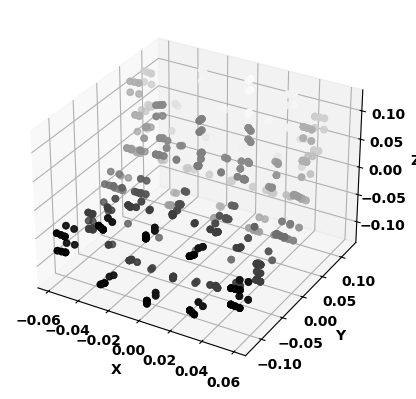

In [52]:
plot_vertices(v_matrix_test_norm)

Now lets compare the covariance matrices of these 2 arrays.

In [53]:
cov_mat = np.round(np.cov(v_matrix, rowvar=False), 4)
cov_mat

array([[ 0.0045, -0.0027,  0.    ],
       [-0.0027,  0.0045, -0.    ],
       [ 0.    , -0.    ,  0.0015]])

In [54]:
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False), 4)
cov_mat_test

array([[ 0.0015, -0.    , -0.    ],
       [-0.    ,  0.0045,  0.0027],
       [-0.    ,  0.0027,  0.0045]])

Similar results to earlier, but this time we should be able to definitively say why the covariance numbers are what they are. In the first example, we observe a weak negative relationship between X and Y. This aligns with our observed vertex orientation. With an increase in X (red axis), we observe a decrease in Y (green axis).

![Sample Object- Vertex Orientation](../img/covariance-analysis-orig-x-y.png)

Likewise, in our second covariance matrix, we observe a weak positive relationship between Y and Z. This too aligns with our observations. We center the mesh at the origin, and look down the +X axis.= at the Y-Z plane.

![Test Object- Vertex Orientation](../img/covariance-analysis-test-y-z.png)

Here too, it makes sense why the covariance is positive. An increase in Y (green axis) is associated with an increase in Z (blue axis). 

Good. We can now ensure axis alignment across Blender and Matplotlib.

The next step is to find the eigenvectors of both our objects' covariance matrices. This will give us the axes along with we have maximum spread. Theoretically speaking, for our sample object, I would expect this to be the unit vectors for +X and +Y- we've already confirmed that the object is oriented to both these axes in Blender, and covariance values did not vary too much across other axes. Lets see.

In [55]:
eg_val, eg_vec = np.linalg.eigh(cov_mat)
eg_vec

array([[ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678],
       [ 1.        , -0.        ,  0.        ]])

In [56]:
eg_val

array([0.0015, 0.0018, 0.0072])

An interesting observation. The number 0.7071 also aligns with a known function - sin or cosine of 45 degrees. This implies that our eigenvectors, or axes of maximum variance are the unit vectors below, along with the positive Z axis.

![Eigen decomposition of the sample object](../img/eigenvector-decomp-sample.png)

From the eigenvalues, we can tell that the direction X=-0.7071, Y=0.7071, Z=0 has the highest observed variance. This corresponds with the blue vector in the image above.

We can also decompose our test object in a similar fashion to get its associated eigenvectors and values.

In [57]:
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
eg_vec_test

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678,  0.70710678],
       [ 0.        ,  0.70710678,  0.70710678]])

In [58]:
eg_val_test

array([0.0015, 0.0018, 0.0072])

Here, we see the unit X vector is the direction of least covariance. The direction of highest covariance is the unit vector X=0, Y=0.7071, Z=0.7071 which, overlayed on our test object looks like the green vector in the image below.

![Eigen decomposition of the test object](../img/eigenvector-decomp-test.png)

Things are starting to make some sense here. However, I see one issue that could pop up to ruin the party. In our sample, the second largest eigenvector pointed away from the object while in our test object this same eigenvector points into it. This is mathematically sound, the vectors are simply scalar multiples of each other, and completely orthogonal- but it would mean that our objects are completely incorrectly rotated in space. Our other 2 eigenvectors will not affect the final output as much, since the object is symmetric in these directions about the centroid.

What's worse, I'm not certain if our eigenvector decomposition is guaranteed to find these exact vectors every time. Since both are valid orthogonal vectors, our algorithm could return either one.

We need a test with an error metric to see whether the vector returned is adequate, or if we need to choose the diametrically opposite one.

An idea inspired by Gemini is to project all the vertices onto our problematic axis and find the mean. We observe that every single point in our object lies entirely above or below our centroid. We do this projection with both our sample object and test object. If the means' signs are aligned, then we have chosen the correct vector. If not, swap it around. Let's see how we might be able to solve this.

We have previously calculated projections by using the @ operator, or dot product.

In [59]:
# projected_v = np.dot(v_matrix_norm, eg_vec[:,1])
projected_v = v_matrix_norm @ eg_vec[:, 1]
np.mean(projected_v)

np.float64(-7.39053788581835e-18)

In [60]:
projected_v_test = v_matrix_test_norm @ eg_vec_test[:, 1]
np.mean(projected_v_test)

np.float64(1.372997705009809e-16)

While the signs are indeed different, I'm not confident in the process since the numbers are so small. Seems like the centroid we've been using in our calculations is different from the centroid in Blender. Our centroid is actually within the shape, not like the one suggested by Blender. Hence, we do get a spread of some positive and some negative numbers when we calculate the mean of the projected points.

A theory I'd like to test out is as follows. Since the pipe bends towards the center, the magnitude of the projected points should be asymmetric- there will be a larger magnitude in one direction of our eigenvector. Lets see on our test object.

In [61]:
np.max(v_matrix_test_norm @ eg_vec_test[:, 1])

np.float64(0.08426762535007683)

In [62]:
np.min(v_matrix_test_norm @ eg_vec_test[:, 1])

np.float64(-0.08430026732376544)

Wow that looks almost exactly the same. What about the sample object? I'd expect this to be same too.

In [63]:
np.max(v_matrix_norm @ eg_vec[:, 1])

np.float64(0.08430028144498089)

In [64]:
np.min(v_matrix_norm @ eg_vec[:, 1])

np.float64(-0.08426831833564255)

Yup. No luck.

## Attempt 3

The goal with todays attempt will be to discretely identify features on the object that will help identify the pose of the object. Let's take a look at our sample object once again in Blender.

![90 Degree Bend Sample 4](../img/90degbend-sample-4.png)

The centroid of this objet, while small, is not the same as the origin, as we have found.

In [65]:
np.mean(v_matrix, axis=0)

array([6.04368129e-02, 6.07087885e-02, 2.46351263e-19])

We got thrown off by the exponents. Rounded to 2 decimals, this is what we see.

In [66]:
np.round(np.mean(v_matrix, axis=0),2)

array([0.06, 0.06, 0.  ])

If we apply this translation onto our shape, we see that the centroid (and thus the centered shape) looks like this.

![90 Degree bend centered vertices](../img/centered-sample-90degbend.png)

This changes the outlook quite a bit. Our centorid is well within the bounds of the shape- in fact its closer to the inside edge than it is the outside. Our eigenvector decomposition now looks like this.

![90 Degree bend centered vertices with eigenvectors](../img/centered-sample-90degbend-egvec.png)

Projecting the points onto the axis looks like this.

![90 Degree bend centered vertices with projected points](../img/centered-sample-90degbend-project.png)

While the lines may not necessarily be exactly 90 degrees, we do see that our max and min values are fairly similar- explaining why our earlier implementation did not work.